In [1]:
import random, platform
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import transformers
from transformers import AutoTokenizer

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

MODEL_NAME = "bert-base-uncased"  
print("transformers:", transformers.__version__)
print("torch       :", torch.__version__)
print("python      :", platform.python_version())
torch.set_num_threads(max(1, torch.get_num_threads()))
print("device      : CPU")
print("CPU threads :", torch.get_num_threads())

transformers: 5.22.2
torch       : 2.14.1+cpu
python      : 3.13.12
device      : CPU
CPU threads : 10


### 1. Load tokenizer

In [3]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
print(type(tokenizer).__name__)
print("Vocab size:", tokenizer.vocab_size)
print("Special tokens:", tokenizer.all_special_tokens)
print("Special token IDs:", tokenizer.all_special_ids)
print("Max model length:", tokenizer.model_max_length)

BertTokenizer
Vocab size: 30522
Special tokens: ['[UNK]', '[SEP]', '[PAD]', '[CLS]', '[MASK]']
Special token IDs: [100, 102, 0, 101, 103]
Max model length: 512


### 2. Calculation Exercise 2
Tokenize `"The cats are playing."`


In [4]:
text = "The cats are playing."

tokens = tokenizer(text, padding=True, truncation=True, return_tensors="pt")

# (a) keys của output
print("tokens.keys():", list(tokens.keys()))
print()
for k, v in tokens.items():
    print(f"{k:16s} shape={tuple(v.shape)}  ->  {v.tolist()}")

tokens.keys(): ['input_ids', 'token_type_ids', 'attention_mask']

input_ids        shape=(1, 7)  ->  [[101, 1996, 8870, 2024, 2652, 1012, 102]]
token_type_ids   shape=(1, 7)  ->  [[0, 0, 0, 0, 0, 0, 0]]
attention_mask   shape=(1, 7)  ->  [[1, 1, 1, 1, 1, 1, 1]]


In [5]:
ids = tokens["input_ids"][0].tolist()
mask = tokens["attention_mask"][0].tolist()
tok_seq = tokenizer.convert_ids_to_tokens(ids)

df = pd.DataFrame({
    "position": range(len(ids)),
    "token": tok_seq,
    "token_id": ids,
    "attention_mask": mask,
    "is_special": [t in tokenizer.all_special_tokens for t in tok_seq],
})
df

,position,token,token_id,attention_mask,is_special
0,0,[CLS],101,1,True
1,1,the,1996,1,False
2,2,cats,8870,1,False
3,3,are,2024,1,False
4,4,playing,2652,1,False
5,5,.,1012,1,False
6,6,[SEP],102,1,True


In [6]:
def count_stats(text, tokenizer):
    enc = tokenizer(text)
    toks = tokenizer.convert_ids_to_tokens(enc["input_ids"])
    content = [t for t in toks if t not in tokenizer.all_special_tokens]   # bỏ [CLS], [SEP]...
    words = text.split()
    # với WordPiece: token bắt đầu bằng '##' là mảnh nối tiếp của một từ
    continuation = [t for t in content if t.startswith("##")]
    return {
        "words (split theo khoảng trắng)": len(words),
        "tokens (tổng, gồm special)": len(toks),
        "tokens (không gồm special)": len(content),
        "special tokens": len(toks) - len(content),
        "subword continuation tokens (##)": len(continuation),
    }

pd.Series(count_stats(text, tokenizer), name="The cats are playing.").to_frame()

,The cats are playing.
words (split theo khoảng trắng),4
"tokens (tổng, gồm special)",7
tokens (không gồm special),5
special tokens,2
subword continuation tokens (##),0


### 3. `input_ids` và `attention_mask`

In [7]:
print("decode (giữ special) :", tokenizer.decode(ids))
print("decode (bỏ special)  :", tokenizer.decode(ids, skip_special_tokens=True))
print()
print("convert_tokens_to_ids('[CLS]') =", tokenizer.convert_tokens_to_ids("[CLS]"))
print("convert_tokens_to_ids('[SEP]') =", tokenizer.convert_tokens_to_ids("[SEP]"))
print("convert_tokens_to_ids('[PAD]') =", tokenizer.convert_tokens_to_ids("[PAD]"))
print("convert_tokens_to_ids('[MASK]')=", tokenizer.convert_tokens_to_ids("[MASK]"))

decode (giữ special) : [CLS] the cats are playing. [SEP]
decode (bỏ special)  : the cats are playing.

convert_tokens_to_ids('[CLS]') = 101
convert_tokens_to_ids('[SEP]') = 102
convert_tokens_to_ids('[PAD]') = 0
convert_tokens_to_ids('[MASK]')= 103


### 4. Subword tokenization

Một từ không nhất thiết tương ứng với một token. Quan sát các từ phổ biến, từ dài, từ hiếm, từ sai chính tả và số.

In [8]:
words = [
    "cat", "cats", "playing", "unbelievable", "unbelievably",
    "tokenization", "pretraining", "electroencephalography",
    "COVID-19", "gooooood", "asdfghjk", "2026", "Hanoi", "phở",
]
rows = []
for w in words:
    pieces = tokenizer.tokenize(w)
    rows.append({
        "word": w,
        "tokens": pieces,
        "#tokens": len(pieces),
        "has_[UNK]": tokenizer.unk_token in pieces,
    })
pd.DataFrame(rows)

,word,tokens,#tokens,has_[UNK]
0,cat,[cat],1,False
1,cats,[cats],1,False
2,playing,[playing],1,False
3,unbelievable,[unbelievable],1,False
4,unbelievably,"[un, ##bel, ##ie, ##va, ##bly]",5,False
5,tokenization,"[token, ##ization]",2,False
6,pretraining,"[pre, ##train, ##ing]",3,False
7,electroencephalography,"[electro, ##ence, ##pha, ##log, ##raphy]",5,False
8,COVID-19,"[co, ##vid, -, 19]",4,False
9,gooooood,"[goo, ##oo, ##ood]",3,False


### 5. Special tokens: một câu và hai câu

In [10]:
single = tokenizer("this movie is great")
pair   = tokenizer("sentence A", "sentence B")

for name, enc in [("Single", single), ("Pair", pair)]:
    toks = tokenizer.convert_ids_to_tokens(enc["input_ids"])
    print(f"{name}")
    print("tokens        :", toks)
    print("token_type_ids:", enc.get("token_type_ids"))
    print("attention_mask:", enc["attention_mask"])
    print()

Single
tokens        : ['[CLS]', 'this', 'movie', 'is', 'great', '[SEP]']
token_type_ids: [0, 0, 0, 0, 0, 0]
attention_mask: [1, 1, 1, 1, 1, 1]

Pair
tokens        : ['[CLS]', 'sentence', 'a', '[SEP]', 'sentence', 'b', '[SEP]']
token_type_ids: [0, 0, 0, 0, 1, 1, 1]
attention_mask: [1, 1, 1, 1, 1, 1, 1]



### 6. Padding và Attention mask

Batch gồm các câu có độ dài khác nhau → phải padding để thành tensor chữ nhật.

In [11]:
batch = [
    "The cat eats fish.",
    "I really did not enjoy this film at all, although the acting was decent.",
    "Great!",
]
enc = tokenizer(batch, padding=True, truncation=True, return_tensors="pt")

print("input_ids shape     :", tuple(enc["input_ids"].shape))
print("attention_mask shape:", tuple(enc["attention_mask"].shape))
print()
for i, s in enumerate(batch):
    toks = tokenizer.convert_ids_to_tokens(enc["input_ids"][i])
    print(f"[{i}] {s}")
    print("    tokens:", toks)
    print("    mask  :", enc["attention_mask"][i].tolist())
    print()

input_ids shape     : (3, 18)
attention_mask shape: (3, 18)

[0] The cat eats fish.
    tokens: ['[CLS]', 'the', 'cat', 'eats', 'fish', '.', '[SEP]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]']
    mask  : [1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

[1] I really did not enjoy this film at all, although the acting was decent.
    tokens: ['[CLS]', 'i', 'really', 'did', 'not', 'enjoy', 'this', 'film', 'at', 'all', ',', 'although', 'the', 'acting', 'was', 'decent', '.', '[SEP]']
    mask  : [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]

[2] Great!
    tokens: ['[CLS]', 'great', '!', '[SEP]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]', '[PAD]']
    mask  : [1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]



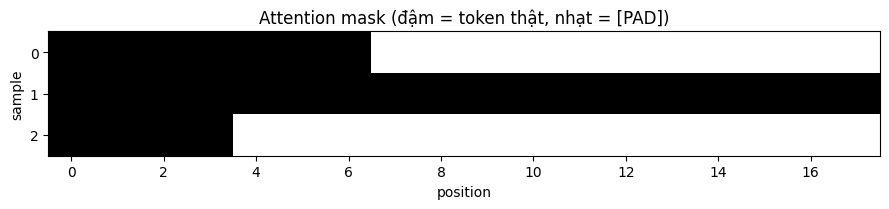

In [12]:
# Trực quan hóa attention mask (trắng = 1 token hợp lệ, đen = padding)
fig, ax = plt.subplots(figsize=(9, 2.2))
ax.imshow(enc["attention_mask"].numpy(), cmap="gray_r", aspect="auto", vmin=0, vmax=1)
ax.set_xlabel("position"); ax.set_ylabel("sample")
ax.set_yticks(range(len(batch)))
ax.set_title("Attention mask (đậm = token thật, nhạt = [PAD])")
plt.tight_layout(); plt.show()

### Kiểm tra ảnh hưởng của padding lên biểu diễn 

Nếu attention mask hoạt động đúng, biểu diễn `[CLS]` của một câu **không** được thay đổi đáng kể khi thêm padding.

In [14]:
from transformers import AutoModel
encoder = AutoModel.from_pretrained(MODEL_NAME).eval()

s = "The cat eats fish."
with torch.no_grad():
    a = tokenizer(s, return_tensors="pt") # không padding
    b = tokenizer(s, padding="max_length", max_length=20, return_tensors="pt")  # padding tới 20

    cls_a = encoder(**a).last_hidden_state[0, 0]
    cls_b = encoder(**b).last_hidden_state[0, 0]
    # cố tình bỏ attention_mask để so sánh
    cls_c = encoder(input_ids=b["input_ids"]).last_hidden_state[0, 0]

cos = torch.nn.functional.cosine_similarity
print("cos(no-pad , pad + mask)    =", cos(cls_a, cls_b, dim=0).item())
print("cos(no-pad , pad, NO mask)  =", cos(cls_a, cls_c, dim=0).item())

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


cos(no-pad , pad + mask)    = 0.9999999403953552
cos(no-pad , pad, NO mask)  = 0.6014702916145325


### 7. Truncation và giới hạn độ dài

In [15]:
long_text = "This movie was surprisingly good, " * 30
for L in [8, 16, 64]:
    e = tokenizer(long_text, truncation=True, max_length=L)
    print(f"max_length={L:3d} -> {len(e['input_ids']):3d} tokens | "
          f"đầu: {tokenizer.convert_ids_to_tokens(e['input_ids'])[:4]} ... "
          f"cuối: {tokenizer.convert_ids_to_tokens(e['input_ids'])[-3:]}")

full = tokenizer(long_text)
print("\nKhông truncation:", len(full["input_ids"]), "tokens")

max_length=  8 ->   8 tokens | đầu: ['[CLS]', 'this', 'movie', 'was'] ... cuối: ['good', ',', '[SEP]']
max_length= 16 ->  16 tokens | đầu: ['[CLS]', 'this', 'movie', 'was'] ... cuối: ['this', 'movie', '[SEP]']
max_length= 64 ->  64 tokens | đầu: ['[CLS]', 'this', 'movie', 'was'] ... cuối: ['this', 'movie', '[SEP]']

Không truncation: 182 tokens


### 8. Thống kê độ dài token trên IMDb 

Dùng `data/IMDB Dataset.csv` trên máy để biết bao nhiêu review bị cắt ở các mức `max_length` 64 / 128 / 256 / 512.

In [ ]:
CANDIDATES = [
    Path("../data/IMDB Dataset.csv"),
    Path("data/IMDB Dataset.csv"),
    Path("IMDB Dataset.csv"),
]
DATA_PATH = next((p for p in CANDIDATES if p.exists()), None)
#print("DATA_PATH:", DATA_PATH.resolve() if DATA_PATH else None)

if DATA_PATH is not None:
    imdb = pd.read_csv(DATA_PATH)
    imdb = imdb.sample(n=min(2000, len(imdb)), random_state=SEED).reset_index(drop=True)
    print(imdb.shape, imdb.columns.tolist())
    display(imdb.head(3))
else:
    print("Không tìm thấy 'IMDB Dataset.csv'. Đã thử:", [str(p) for p in CANDIDATES])
    print("Sửa DATA_PATH thành đường dẫn đúng trên máy của bạn.")
    imdb = None

(2000, 2) ['review', 'sentiment']


,review,sentiment
0,I really liked this Summerslam due to the look...,positive
1,Not many television shows appeal to quite as m...,positive
2,The film quickly gets to a major chase scene w...,negative


In [19]:
if imdb is not None:
    # IMDb có thẻ HTML như <br />; 
    n_html = imdb["review"].str.contains("<br />", regex=False).sum()
    print(f"Review chứa '<br />': {n_html}/{len(imdb)}")

    lengths = [len(x) for x in tokenizer(imdb["review"].tolist(), truncation=False)["input_ids"]]
    imdb["n_tokens"] = lengths
    imdb["n_words"] = imdb["review"].str.split().str.len()

    print(imdb[["n_words", "n_tokens"]].describe().round(1))
    print("\ntokens / words (trung bình):", round((imdb["n_tokens"] / imdb["n_words"]).mean(), 2))

    rows = []
    for L in [64, 128, 256, 512]:
        rows.append({"max_length": L,
                     "% review bị cắt": round((imdb["n_tokens"] > L).mean() * 100, 1)})
    display(pd.DataFrame(rows))

Review chứa '<br />': 1172/2000


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (798 > 512). Running this sequence through the model will result in indexing errors


       n_words  n_tokens
count   2000.0    2000.0
mean     232.1     311.8
std      172.0     232.9
min       19.0      30.0
25%      124.0     165.0
50%      174.0     232.0
75%      283.2     375.2
max     1010.0    1545.0

tokens / words (trung bình): 1.34


,max_length,% review bị cắt
0,64,98.4
1,128,88.5
2,256,43.6
3,512,15.0


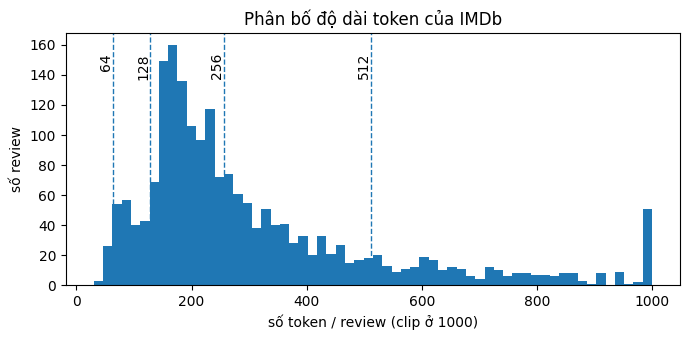

In [20]:
if imdb is not None:
    plt.figure(figsize=(7, 3.5))
    plt.hist(imdb["n_tokens"].clip(upper=1000), bins=60)
    for L in [64, 128, 256, 512]:
        plt.axvline(L, linestyle="--", linewidth=1)
        plt.text(L, plt.ylim()[1] * 0.92, str(L), rotation=90, va="top", ha="right")
    plt.xlabel("số token / review (clip ở 1000)"); plt.ylabel("số review")
    plt.title("Phân bố độ dài token của IMDb")
    plt.tight_layout(); plt.savefig("token_length_distribution.png", dpi=150); plt.show()